# DistilBERT - Zero-Shot Cross-Dataset Evaluation on Enron


## 0. Install dependencies

In [1]:
!pip install -q transformers[torch] scikit-learn matplotlib seaborn tqdm

## 1. Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 2. Imports & configuration

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset, DataLoader

from transformers import (
    DistilBertTokenizerFast,
    DistilBertForSequenceClassification,
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score,
    confusion_matrix, roc_curve,
)

warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU    : {torch.cuda.get_device_name(0)}')

BASE_DIR    = '/content/drive/MyDrive/Phishing_Email'

AVN_MODEL_DIR = f'{BASE_DIR}/models/distilbert_saved'

ENRON_PATH  = f'{BASE_DIR}/final_dataset/Enron_preprocessed.csv'

RESULTS_DIR = f'{BASE_DIR}/results'
os.makedirs(RESULTS_DIR, exist_ok=True)

MAX_LEN    = 128
BATCH_SIZE = 64
THRESHOLD  = 0.5

print('Config loaded ✓')

Device : cuda
GPU    : Tesla T4
Config loaded ✓


## 3. Load AVN-trained DistilBERT model & tokenizer

In [4]:
assert os.path.isdir(AVN_MODEL_DIR), (
    f'AVN model directory not found: {AVN_MODEL_DIR}\n'
    'Run the AVN DistilBERT training notebook first and make sure it saves to this path.'
)

tokenizer = DistilBertTokenizerFast.from_pretrained(AVN_MODEL_DIR)
model     = DistilBertForSequenceClassification.from_pretrained(AVN_MODEL_DIR)
model.to(DEVICE)
model.eval()

print('AVN-trained DistilBERT loaded ✓')
print(f'Model device : {next(model.parameters()).device}')

Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

AVN-trained DistilBERT loaded ✓
Model device : cuda:0


## 4. Load full Enron dataset

In [5]:
df = pd.read_csv(ENRON_PATH)
print('Raw shape :', df.shape)
df.head(2)


Raw shape : (28256, 10)


,label,clean_text,word_count,avg_word_length,url_like_count,text_entropy,action_density,has_attachment,repeated_char_patterns,writing_error_total
0,0,see attached file hplno xl hplno xl,7,4.142857,0,4.112720,0.133333,1,0,12
1,0,forwarded sabrae zajac hou ect pm enron capita...,144,4.944444,0,4.604621,0.053991,0,1,16


In [6]:
assert 'clean_text' in df.columns, "'clean_text' column missing - run Enron preprocessing first"
assert 'label'      in df.columns, "'label' column missing"

df = df.dropna(subset=['clean_text', 'label']).reset_index(drop=True)
df['label'] = df['label'].astype(int)

print(f'Evaluation set : {len(df):,} rows')
print('Label distribution :')
print(df['label'].value_counts().to_string())

texts  = df['clean_text'].astype(str).tolist()
labels = df['label'].tolist()

Evaluation set : 28,255 rows
Label distribution :
label
0    14535
1    13720


## 5. EDA - class distribution

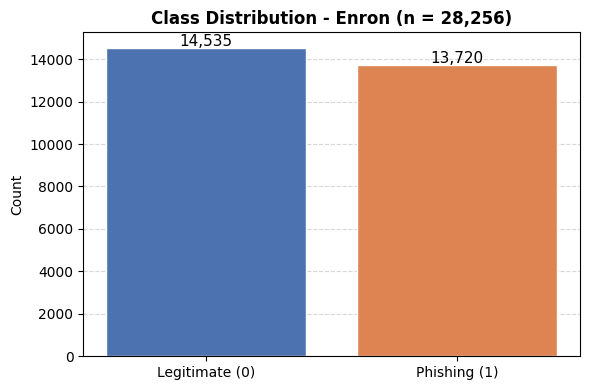

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
counts  = df['label'].value_counts().sort_index()
bars    = ax.bar(['Legitimate (0)', 'Phishing (1)'], counts.values,
                 color=['#4C72B0', '#DD8452'], edgecolor='white')
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 80,
            f'{v:,}', ha='center', fontsize=11)
ax.set_title('Class Distribution - Enron (n = 28,256)', fontweight='bold')
ax.set_ylabel('Count')
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/enron_distilbert_class_dist.jpg',
            dpi=150, bbox_inches='tight', pil_kwargs={'quality': 92})
plt.show()
plt.close(fig)


## 6. Tokenise & build DataLoader

In [8]:
class InferenceDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt',
        )
        return {
            'input_ids'     : enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'label'         : torch.tensor(self.labels[idx], dtype=torch.long),
        }

enron_dataset = InferenceDataset(texts, labels, tokenizer, MAX_LEN)
enron_loader  = DataLoader(enron_dataset, batch_size=BATCH_SIZE,
                           shuffle=False, num_workers=2, pin_memory=True)

print(f'Inference batches : {len(enron_loader)}')

Inference batches : 442


## 7. Zero-shot inference on Enron

> **No retraining. No fine-tuning. AVN-fitted parameters only.**
> Threshold = 0.5 fixed on AVN training data.


In [9]:
all_probs  = []
all_labels = []
inference_times = []

model.eval()
with torch.no_grad():
    for batch in tqdm(enron_loader, desc='Inference'):
        input_ids      = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        batch_labels   = batch['label'].numpy().tolist()

        t0      = time.perf_counter()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        t1      = time.perf_counter()

        probs = torch.softmax(outputs.logits, dim=-1)[:, 1].cpu().numpy()
        all_probs .extend(probs.tolist())
        all_labels.extend(batch_labels)
        inference_times.append((t1 - t0) / len(batch_labels))

mean_inference_time = np.mean(inference_times)
print(f'Inference complete ✓')
print(f'Mean inference time per email : {mean_inference_time:.4f} s')

Inference:   0%|          | 0/442 [00:00<?, ?it/s]

Inference complete ✓
Mean inference time per email : 0.0034 s


## 8. Apply threshold = 0.5 & compute metrics

In [10]:
y_true = np.array(all_labels)
y_prob = np.array(all_probs)
y_pred = (y_prob >= THRESHOLD).astype(int)

accuracy  = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall    = recall_score(y_true, y_pred, zero_division=0)
f1        = f1_score(y_true, y_pred, zero_division=0)
roc_auc   = roc_auc_score(y_true, y_prob)

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print('=' * 60)
print('  DistilBERT - Zero-Shot Cross-Dataset Results')
print('  Trained on: AVN  |  Evaluated on: Enron (n = 28,256)')
print('  Threshold = 0.5  (fixed on AVN training data)')
print('=' * 60)
print(f'  Accuracy           : {accuracy:.4f}  ({accuracy*100:.2f}%)')
print(f'  Precision          : {precision:.4f}  ({precision*100:.2f}%)')
print(f'  Recall             : {recall:.4f}  ({recall*100:.2f}%)')
print(f'  F1-score           : {f1:.4f}  ({f1*100:.2f}%)')
print(f'  ROC-AUC            : {roc_auc:.4f}')
print(f'  False Positives    : {fp:,}')
print(f'  False Negatives    : {fn:,}')
print(f'  Mean infer. time   : {mean_inference_time:.4f} s/email')
print('=' * 60)

  DistilBERT - Zero-Shot Cross-Dataset Results
  Trained on: AVN  |  Evaluated on: Enron (n = 28,256)
  Threshold = 0.5  (fixed on AVN training data)
  Accuracy           : 0.7850  (78.50%)
  Precision          : 0.8247  (82.47%)
  Recall             : 0.7076  (70.76%)
  F1-score           : 0.7617  (76.17%)
  ROC-AUC            : 0.8605
  False Positives    : 2,064
  False Negatives    : 4,012
  Mean infer. time   : 0.0034 s/email


## 9. Save results to CSV

In [11]:
results_row = {
    'Model'              : 'DistilBERT',
    'Train dataset'      : 'AVN',
    'Eval dataset'       : 'Enron',
    'n_eval'             : len(y_true),
    'Protocol'           : 'Zero-shot (AVN-fitted params)',
    'Threshold'          : THRESHOLD,
    'Accuracy'           : f'{accuracy*100:.2f}%',
    'Precision'          : f'{precision*100:.2f}%',
    'Recall'             : f'{recall*100:.2f}%',
    'F1-score'           : f'{f1*100:.2f}%',
    'ROC-AUC'            : f'{roc_auc:.4f}',
    'False Positives'    : int(fp),
    'False Negatives'    : int(fn),
    'Mean inference time': f'{mean_inference_time:.4f} s/email',
}

results_csv = f'{RESULTS_DIR}/enron_distilbert_zeroshot_results.csv'
pd.DataFrame([results_row]).to_csv(results_csv, index=False)
print(f'Results saved → {results_csv}')


Results saved → /content/drive/MyDrive/Phishing_Email/results/enron_distilbert_zeroshot_results.csv


## 10. Confusion matrix & ROC curve

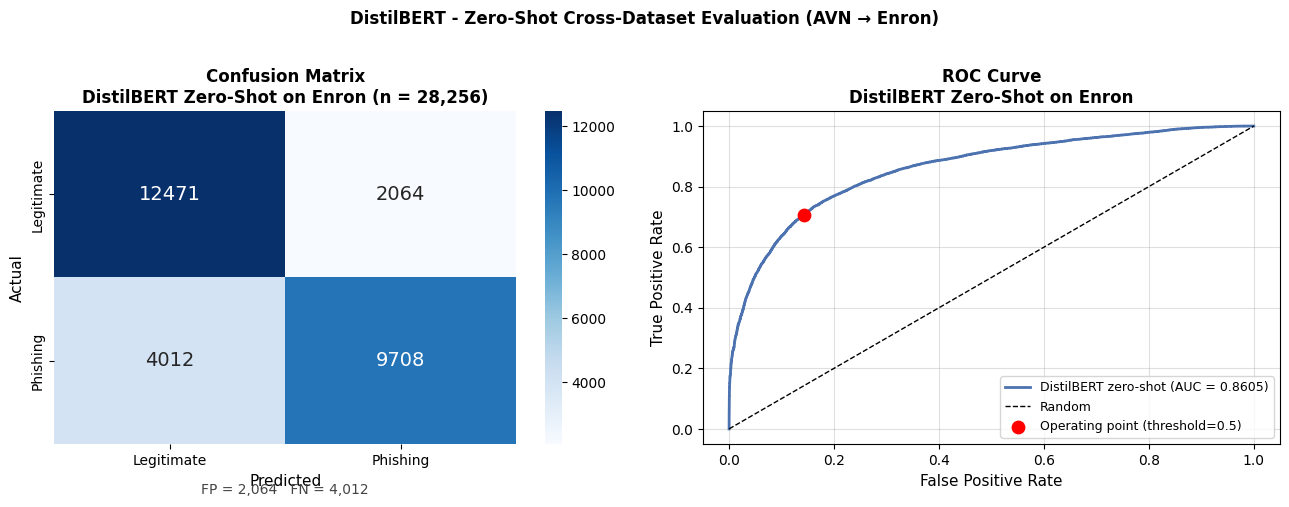

Eval plots saved → /content/drive/MyDrive/Phishing_Email/results/enron_distilbert_zeroshot_eval.jpg


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Legitimate', 'Phishing'],
    yticklabels=['Legitimate', 'Phishing'],
    ax=axes[0],
    annot_kws={'size': 14},
)
axes[0].set_title(
    'Confusion Matrix\nDistilBERT Zero-Shot on Enron (n = 28,256)',
    fontweight='bold',
)
axes[0].set_xlabel('Predicted', fontsize=11)
axes[0].set_ylabel('Actual',    fontsize=11)

axes[0].text(0.5, -0.15,
    f'FP = {fp:,}   FN = {fn:,}',
    ha='center', transform=axes[0].transAxes, fontsize=10, color='#444'
)

fpr, tpr, _ = roc_curve(y_true, y_prob)
axes[1].plot(fpr, tpr, color='#4C72B0', lw=2,
             label=f'DistilBERT zero-shot (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
axes[1].scatter([fp / (fp + tn)], [tp / (tp + fn)],
               color='red', zorder=5, s=80,
               label=f'Operating point (threshold={THRESHOLD})')
axes[1].set_title(
    'ROC Curve\nDistilBERT Zero-Shot on Enron',
    fontweight='bold',
)
axes[1].set_xlabel('False Positive Rate', fontsize=11)
axes[1].set_ylabel('True Positive Rate',  fontsize=11)
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(alpha=0.4)

plt.suptitle(
    'DistilBERT - Zero-Shot Cross-Dataset Evaluation (AVN → Enron)',
    fontsize=12, fontweight='bold', y=1.02,
)
plt.tight_layout()
eval_path = f'{RESULTS_DIR}/enron_distilbert_zeroshot_eval.jpg'
fig.savefig(eval_path, dpi=150, bbox_inches='tight',
            pil_kwargs={'quality': 92})
plt.show()
plt.close(fig)
print(f'Eval plots saved → {eval_path}')

## 11. Summary table

> For comparison with Linear SVM and Random Forest results from the same zero-shot protocol.


In [13]:
summary = pd.DataFrame({
    'Metric'               : ['Accuracy', 'Precision', 'Recall', 'F1-score',
                               'False Positives', 'False Negatives',
                               'Mean inference time'],
    'DistilBERT (zero-shot)': [
        f'{accuracy*100:.2f}%',
        f'{precision*100:.2f}%',
        f'{recall*100:.2f}%',
        f'{f1*100:.2f}%',
        str(fp),
        str(fn),
        f'{mean_inference_time:.4f} s/email',
    ],
    'Linear SVM &' : ['80.24%', '80.85%', '77.71%', '79.25%',
                                '2,525', '3,058', '-'],
    'SVM-RF Ensemble': ['81.45%', '84.36%', '75.85%', '79.88%',
                                    '1,929', '3,313', '0.039 s/email'],
})

print(summary.to_string(index=False))
summary.to_csv(
    f'{RESULTS_DIR}/enron_distilbert_zeroshot_summary_table.csv',
    index=False
)
print(f'\nSummary table saved → {RESULTS_DIR}/enron_distilbert_zeroshot_summary_table.csv')

             Metric DistilBERT (zero-shot) Linear SVM & SVM-RF Ensemble
           Accuracy                 78.50%       80.24%          81.45%
          Precision                 82.47%       80.85%          84.36%
             Recall                 70.76%       77.71%          75.85%
           F1-score                 76.17%       79.25%          79.88%
    False Positives                   2064        2,525           1,929
    False Negatives                   4012        3,058           3,313
Mean inference time         0.0034 s/email            -   0.039 s/email

Summary table saved → /content/drive/MyDrive/Phishing_Email/results/enron_distilbert_zeroshot_summary_table.csv


## 12. Per-class breakdown

In [14]:
from sklearn.metrics import classification_report
print(classification_report(
    y_true, y_pred,
    target_names=['Legitimate (0)', 'Phishing (1)'],
    digits=4,
))

                precision    recall  f1-score   support

Legitimate (0)     0.7566    0.8580    0.8041     14535
  Phishing (1)     0.8247    0.7076    0.7617     13720

      accuracy                         0.7850     28255
     macro avg     0.7906    0.7828    0.7829     28255
  weighted avg     0.7897    0.7850    0.7835     28255

